# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os 
import numpy as np
import sys

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '../../src/troutpy_reproducibility'))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from batch_running import *

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


##  Batch running of the pipeline

In [2]:
def run_exrna_analysis_pipeline(
    inpath: str,
    binsize: int = 3,
    background_filter: float = 0.4,
    gaussian_kernel_key: float = 2.0,
    sainsc_threads: int = 16,
    percentile_threshold: float = 10,
    square_size: float = 10,
    min_counts_env: int = 5,
    spatial_var_neighbors: int = 10,
    colocalization_threshold: int = 1,
    min_logfoldratio: float = 0.0,
    lambda_decay: float = 0.1,
    source_njobs: int = 10,
    diffusion_params: dict = None,
    scatter_params: list = None,
    spatial_map_categories: list = None,
    spatial_map_top: int = 3,
    spatial_map_bottom: int = 3,
    spot_size_cells: float = 10,
    spot_size_extra: float = 15,
    **kwargs,
) -> None:
    """
    Runs the full extracellular RNA analysis pipeline and saves outputs.

    Parameters
    ----------
    inpath : str
        Path to the folder containing data.zarr and metadata.csv.
    binsize : int
        Bin size for segmentation-free SAiNSC.
    background_filter : float
        Background filter threshold for SAiNSC.
    gaussian_kernel_key : float
        Gaussian kernel sigma for SAiNSC.
    sainsc_threads : int
        Number of threads for SAiNSC.
    percentile_threshold : float
        Percentile threshold to define extracellular transcripts.
    square_size : float
        Square size (microns) to aggregate extracellular transcripts.
    min_counts_env : int
        Minimum counts to estimate environment neighbors.
    spatial_var_neighbors : int
        Number of neighbors for spatial variability.
    colocalization_threshold : int
        Threshold for spatial colocalization.
    min_logfoldratio : float
        Minimum logfoldratio_over_noise for filtering exRNA.
    lambda_decay : float
        Decay constant for source score computation.
    source_njobs : int
        Number of jobs for computing source scores.
    diffusion_params : dict
        Parameters for diffusion_results plotting.
    scatter_params : list
        List of tuples for metric_scatter: (x, y, top_x, top_y, bot_x, bot_y).
    spatial_map_categories : list
        List of metadata var names for spatial in/out maps.
    spatial_map_top : int
        Number of top genes per category.
    spatial_map_bottom : int
        Number of bottom genes per category.
    spot_size_cells : float
        Spot size for cells layer in spatial maps.
    spot_size_extra : float
        Spot size for extra layer in spatial maps.
    """
    # Prepare paths
    figures_path = os.path.join(inpath, "figures")
    os.makedirs(figures_path, exist_ok=True)
    zarr_path = os.path.join(inpath, "data.zarr")
    meta_path = os.path.join(inpath, "metadata.csv")

    # Load data
    sdata = sd.read_zarr(zarr_path) if hasattr(sd, "read_zarr") else SpatialData.read(zarr_path)
    metadata = pd.read_csv(meta_path)

    # redefine overlaps_cell in transcripts, for nuclei
    if "nuclei" in metadata["segmentation_method"][0]:
        transcripts = sdata["transcripts"].compute()
        transcripts["overlaps_cell"] = transcripts["overlaps_nucleus"].astype(bool)
        sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)
        print("Redefined overlaps_cell in transcripts using nuclei segmentation.")

    # 1) Clustering
    clustering_pipeline(sdata)

    # 2) Segmentation-free SAiNSC
    troutpy.pp.segmentation_free_sainsc(
        sdata,
        binsize=binsize,
        celltype_key="leiden",
        background_filter=background_filter,
        gaussian_kernel_key=gaussian_kernel_key,
        n_threads=sainsc_threads)

    # 3) Histogram of scores
    troutpy.pl.histogram(
        sdata, x="cosine_similarity", hue="overlaps_cell", palette="troutpy", save=True, figures_path=figures_path
    )

    # 4) Define extracellular
    troutpy.pp.define_extracellular(
        sdata, layer="transcripts", method="sainsc", copy=False, percentile_threshold=percentile_threshold
    )

    # 5) Crosstab / pie / heatmap
    troutpy.pl.crosstab(
        sdata,
        yvar="extracellular",
        xvar="overlaps_cell",
        normalize=False,
        cmap="troutpy",
        kind="barh",
        stacked=True,
        save=True,
        figures_path=figures_path,
        figsize=(5, 2),
    )
    troutpy.pl.pie(
        sdata, groupby="match_cell_signature", group_key="overlaps_cell", palette="troutpy", figures_path=figures_path
    )
    troutpy.pl.crosstab(
        sdata,
        xvar="extracellular",
        yvar="overlaps_cell",
        normalize=True,
        cmap="Aquas",
        kind="heatmap",
        stacked=True,
        save=True,
        figures_path=figures_path,
    )

    # 6) Single-value outputs
    proportion_of_segmented = (sdata["transcripts"]["overlaps_cell"].compute() == True).sum() / len(sdata["transcripts"]["extracellular"].compute())
    proportion_of_extracellular = (sdata["transcripts"]["extracellular"].compute() == True).sum() / len(sdata["transcripts"]["extracellular"].compute())

    # 7) Aggregate extracellular
    troutpy.pp.aggregate_extracellular_transcripts(sdata, gene_key="gene", square_size=square_size)

    # 8) Estimate neighbors
    nneighbors = estimate_environment_neighbors(
        sdata, cell_key="table", env_key="segmentation_free_table", min_counts=min_counts_env, plot=False
    )

    # 9) Spatial statistics
    #print(np.sum(sdata['xrna_metadata'].var['control_probe']==True))
    troutpy.tl.quantify_overexpression(sdata, codeword_key="control_probe", control_codewords=[True], gene_key="gene",percentile_threshold=99)
    troutpy.tl.extracellular_enrichment(sdata, gene_key="gene")
    troutpy.tl.spatial_variability(
        sdata,
        gene_key="gene",
        n_neighbors=spatial_var_neighbors,
        square_size=2 * square_size,  # for variability you might double the window
    )
    troutpy.tl.in_out_correlation(sdata, n_neighbors=nneighbors)
    troutpy.tl.spatial_colocalization(sdata, threshold_colocalized=colocalization_threshold, copy=False)

    sdata["xrna_metadata"].var["control_probe"] = sdata["xrna_metadata"].var["control_probe"].astype(bool)

    # 10) Save intermediate
    sdata.write(os.path.join(inpath, "data_processed.zarr"), overwrite=True)
    genes_prop_over_noise = (sdata["xrna_metadata"].var["logfoldratio_over_noise"] > 0).sum() / sdata["xrna_metadata"].var.shape[0]

    #
    gene_info=sdata["xrna_metadata"].var
    non_noise_genes=gene_info[gene_info['logfoldratio_over_noise']<0].index
    all_gene_ids=sdata['extracellular_transcripts']['gene'].compute()
    noise_RNA_proportion=np.sum(all_gene_ids.isin(non_noise_genes))/len(all_gene_ids)
    
    # 11) Filter exRNA
    troutpy.pp.filter_xrna(sdata, min_logfoldratio_over_noise=min_logfoldratio, gene_key="gene")
    troutpy.pp.filter_xrna(sdata,gene_key="gene",control_probe=True)
    troutpy.pp.filter_xrna(sdata,gene_key="gene",genes_in_segmented=False)

    # 12) Source score + diffusion + plotting
    troutpy.tl.compute_source_score(sdata,layer="transcripts",gene_key="gene",
        lambda_decay=lambda_decay,copy=False,celltype_key="leiden",n_jobs=source_njobs)

    troutpy.tl.assess_diffussion(sdata, gene_key="gene", distance_key="distance")

    # Diffusion plot
    if diffusion_params is None:
        diffusion_params = {}
    troutpy.pl.diffusion_results(sdata, **(diffusion_params or {}), save=True, figures_path=figures_path)

    # Scatter plots
    if scatter_params is None:
        scatter_params = [
            ("mean_displacement", "extracellular_proportion", 1, 10, 0, 0),
            ("mean_displacement", "in_out_spearmanR", 1, 10, 0, 0),
        ]
    for x, y, top_x, top_y, bot_x, bot_y in scatter_params:
        troutpy.pl.metric_scatter(
            sdata,
            x=x,
            y=y,
            label_top_n_x=top_x,
            label_top_n_y=top_y,
            label_bottom_n_x=bot_x,
            label_bottom_n_y=bot_y,
            figures_path=figures_path,size=5,
            save=True,
        )

    # 13) Final save
    sdata.write(os.path.join(inpath, "data_processed_filtered.zarr"), overwrite=True)

    # 14) Summarize key scalars

    proportion_non_diffussion = (sdata["xrna_metadata"].var["ks_pval"] < 0.05).sum() / len(sdata["xrna_metadata"].var.index)
    mean_gene_displacement = sdata["xrna_metadata"].var["mean_displacement"].mean()
    
    # non-noise_RNA_proportion
    gene_info=sdata["xrna_metadata"].var
    non_diffussion_genes=gene_info[gene_info['ks_pval']<0.05].index
    all_gene_ids=sdata['extracellular_transcripts']['gene'].compute()
    diffussion_RNA_proportion=1-np.sum(all_gene_ids.isin(non_diffussion_genes))/len(all_gene_ids)
    
    # 15) Spatial maps
    if spatial_map_categories is None:
        spatial_map_categories = [
            "mean_displacement",
            "logfoldratio_over_noise",
            "in_out_spearmanR",
            "moran_I",
            "extracellular_proportion",
            "proportion_of_colocalized",
        ]
    batch_spatial_inout_maps(
        sdata=sdata,
        metadata_layer="xrna_metadata",
        variables=spatial_map_categories,
        output_dir=os.path.join(figures_path, "spatial_maps"),
        n_top=spatial_map_top,
        n_bottom=spatial_map_bottom,
        spot_size_cells=spot_size_cells,
        spot_size_extra=spot_size_extra,
    )


    # 16) Save summary
    summary = pd.DataFrame(
        {
            "proportion_of_segmented": [proportion_of_segmented],
            "proportion_of_extracellular": [proportion_of_extracellular],
            "environment_n_neighbors": [nneighbors],
            "genes_prop_over_noise": [genes_prop_over_noise],
            "proportion_non_diffussion": [proportion_non_diffussion],
            "mean_gene_displacement": [mean_gene_displacement],
            "noise_RNA_proportion":[noise_RNA_proportion],
            "diffussion_RNA_proportion":[diffussion_RNA_proportion],
        }
    )
    summary.to_csv(os.path.join(figures_path, "pipeline_summary.csv"), index=False)

    print(f"Pipeline completed. Figures and summary saved in {figures_path}")

## Run the main analysis workflow

In [3]:
main_path = "/media/sergio/Meninges/troutpy/rois/"
files = os.listdir(main_path)

In [ ]:
files[6:7]

['merscope_hsuterine',
 'xenium_hsfemur',
 'xenium_hsheart',
 'xenium_hsprostate',
 'xenium_hsputamen',
 'xenium_hsskin_5k',
 'xenium_msbrain_300',
 'xenium_msbrain_5k',
 'xenium_msbrain_5k_large',
 'xenium_mscolon_5k']

In [6]:
files=files[6:7]

In [4]:
files=files[-1:]

In [34]:
files=files[11:12]

In [16]:
files=files[-3:-2]

/media/sergio/Meninges/troutpy/rois/merscope_hsuterine
Proportion of cells retained after filtering: 99.66%


2025-06-05 09:45:58.059841: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-06-05 09:45:58.075088: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1749109558.091130 2595068 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1749109558.095638 2595068 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1749109558.108892 2595068 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

Final adata shape: (11393, 500)


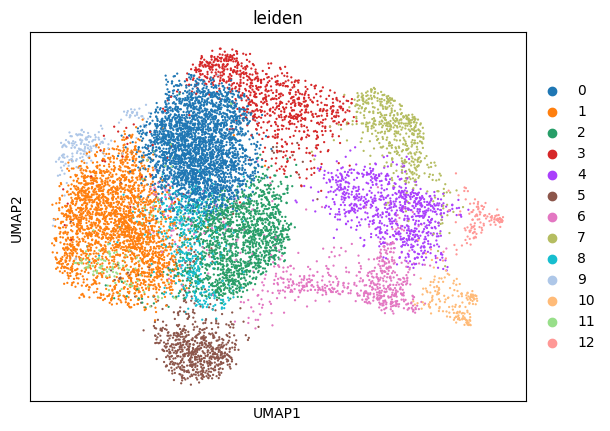

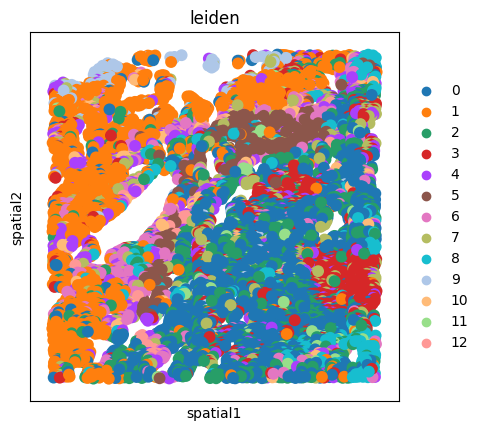

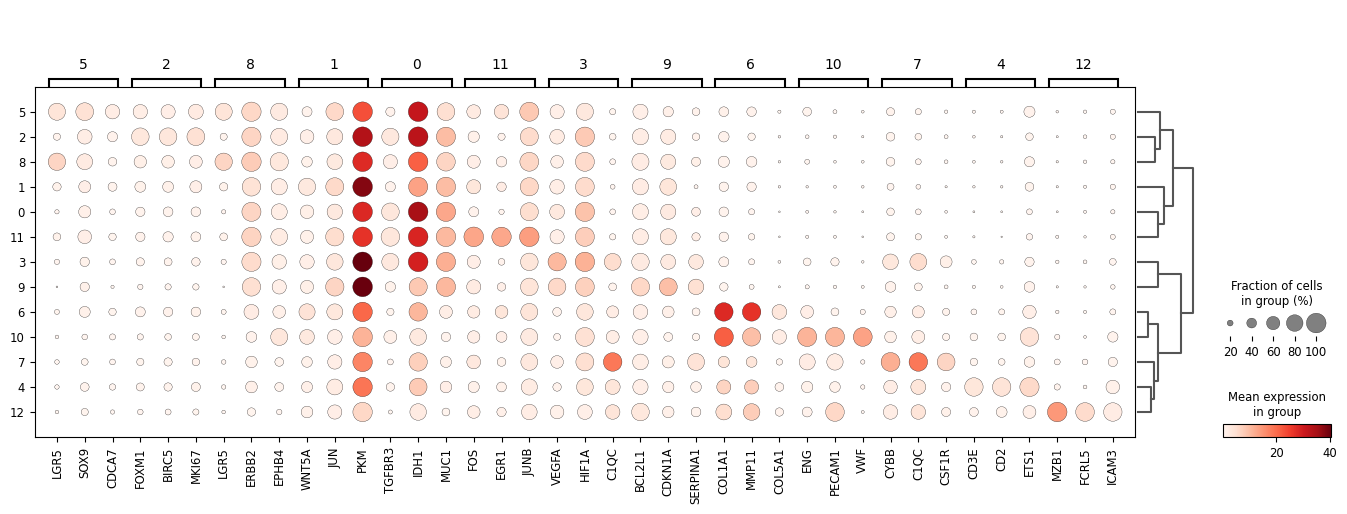

Cosine similarity threshold for extracellular definition: 0.7712834477424622
Added 'xrna_metadata' table with 550 unique genes to the SpatialData object.
Using precomputed segmentation free table
INFO     The Zarr backing store has been changed from                                                              
         /media/sergio/Meninges/troutpy/rois/merscope_hsuterine/data.zarr the new file path:                       
         /media/sergio/Meninges/troutpy/rois/merscope_hsuterine/data_processed.zarr                                


Processing genes: 100%|██████████| 268/268 [06:53<00:00,  1.54s/it]
Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


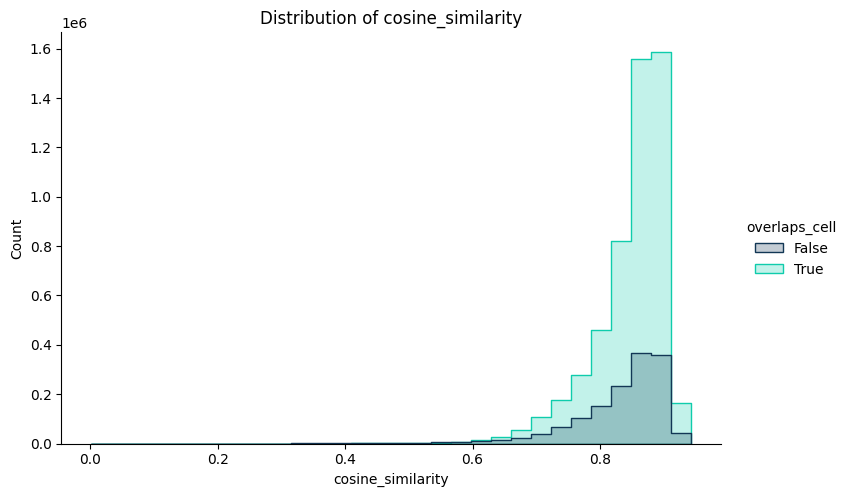

<Figure size 500x200 with 0 Axes>

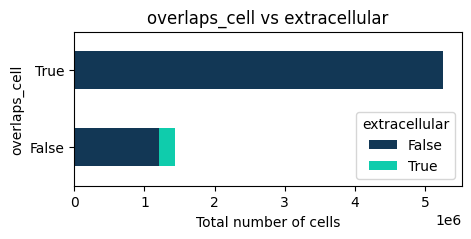

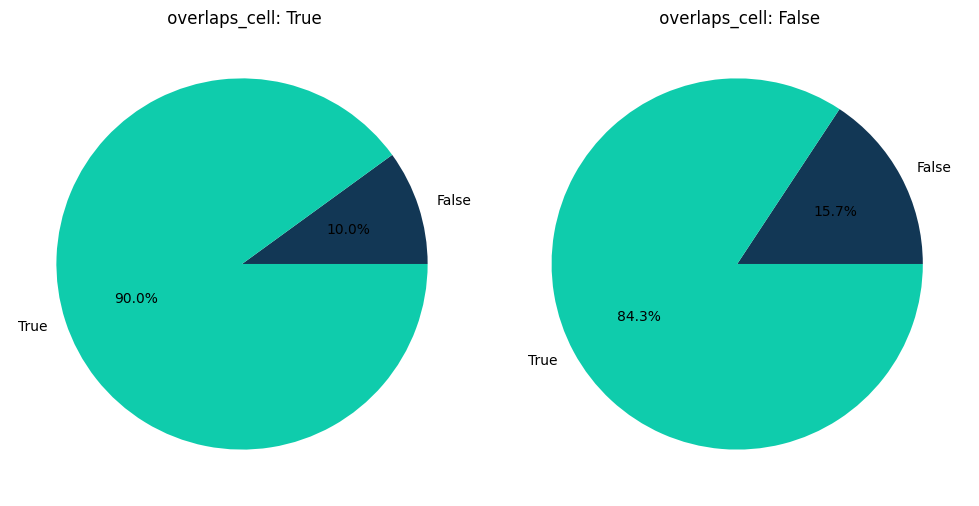

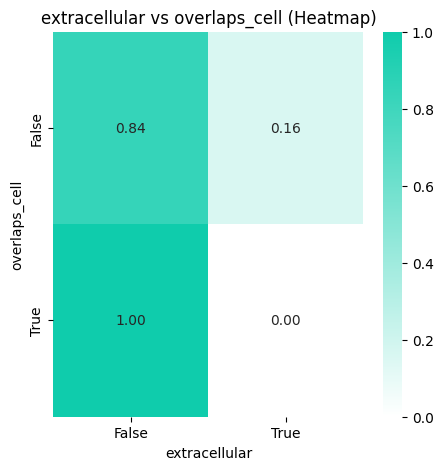

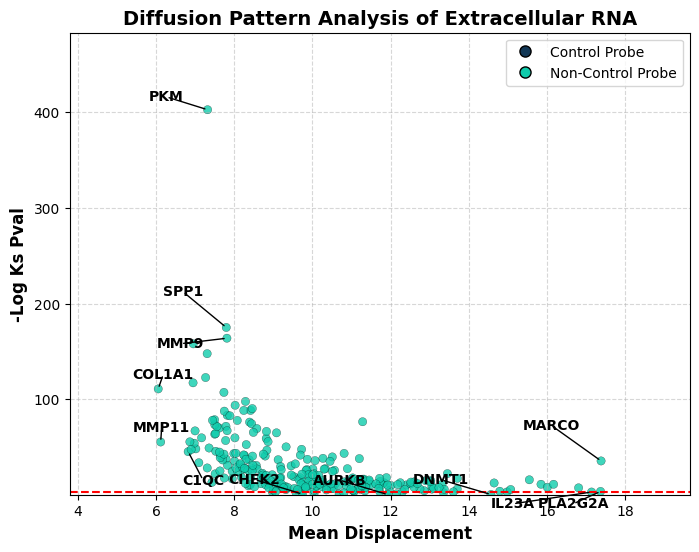

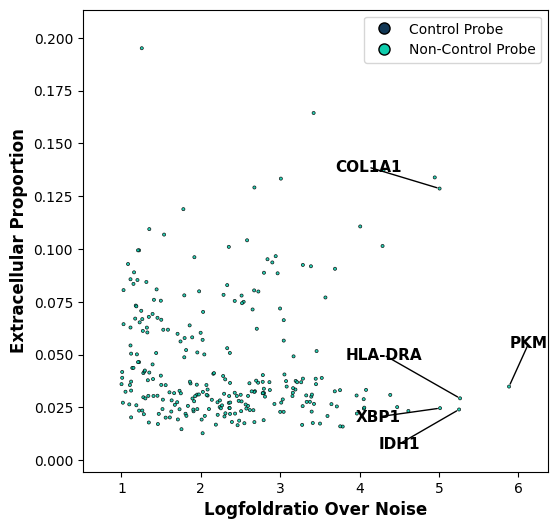

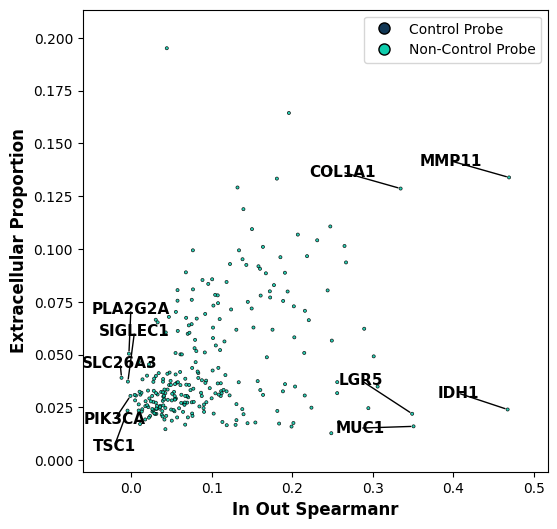

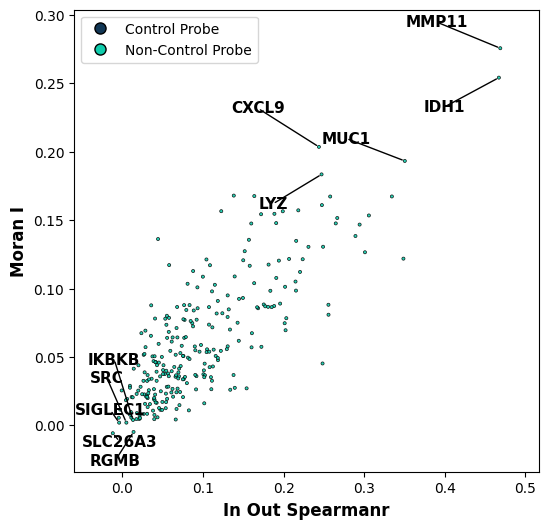

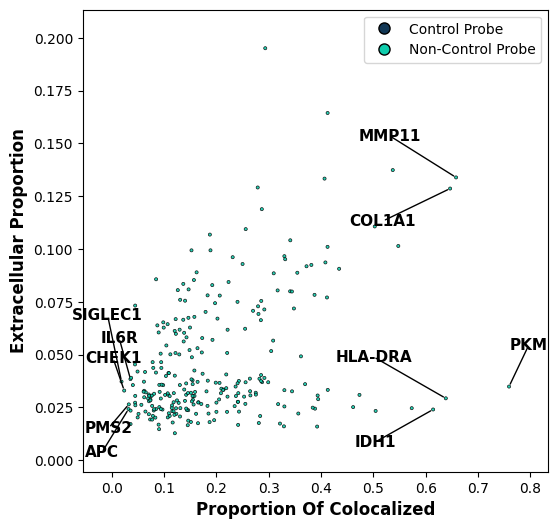

INFO     The Zarr backing store has been changed from                                                              
         /media/sergio/Meninges/troutpy/rois/merscope_hsuterine/data_processed.zarr the new file path:             
         /media/sergio/Meninges/troutpy/rois/merscope_hsuterine/data_processed_filtered.zarr                       
Pipeline completed. Figures and summary saved in /media/sergio/Meninges/troutpy/rois/merscope_hsuterine/figures


In [7]:
for file in files:
    inpath = os.path.join(main_path, file)
    print(inpath)
    #try:
    run_exrna_analysis_pipeline(
        inpath=inpath,
        binsize=3,  # SAiNSC bin size
        background_filter=0.4,  # SAiNSC background threshold
        gaussian_kernel_key=2.0,  # SAiNSC Gaussian sigma
        sainsc_threads=1,  # Number of threads for SAiNSC
        percentile_threshold=10,  # Percentile to call extracellular
        square_size=10,  # Microns for aggregation bins
        min_counts_env=5,  # Min counts for neighbor estimate
        spatial_var_neighbors=10,  # Neighbors for spatial variability
        colocalization_threshold=1,  # Threshold for colocalization
        min_logfoldratio=0.0,  # Filter threshold on logfoldratio
        lambda_decay=0.1,  # Decay constant for source scoring
        source_njobs=1,  # Jobs for compute_source_score
        diffusion_params={  # Any extra args for diffusion_results
            "x_col": "mean_displacement",
            "y_col": "-log_ks_pval",
            "label_top_n_x": 3,
            "label_top_n_y": 3,
            "label_bottom_n_x": 3,
            "label_bottom_n_y": 3,
            "y_logscale": False,
            "title": None,
            "palette": "troutpy",
        },
        scatter_params=[  # List of metric_scatter calls
            ("logfoldratio_over_noise", "extracellular_proportion", 5, 0, 0, 0),
            ("in_out_spearmanR", "extracellular_proportion", 5, 0, 5, 0),
            ("in_out_spearmanR", "moran_I", 0, 5, 0, 5),
            ("proportion_of_colocalized", "extracellular_proportion", 5, 0, 5, 0),
        ],
        spatial_map_categories=[
            "mean_displacement",
            "logfoldratio_over_noise",
            "in_out_spearmanR",
            "moran_I",
            "extracellular_proportion",
            "proportion_of_colocalized",
        ],
        spatial_map_top=3,
        spatial_map_bottom=3,
        spot_size_cells=10,
        spot_size_extra=15,
    )
    #except:
    #    print('not possible to run')

### Divided run pipeline 

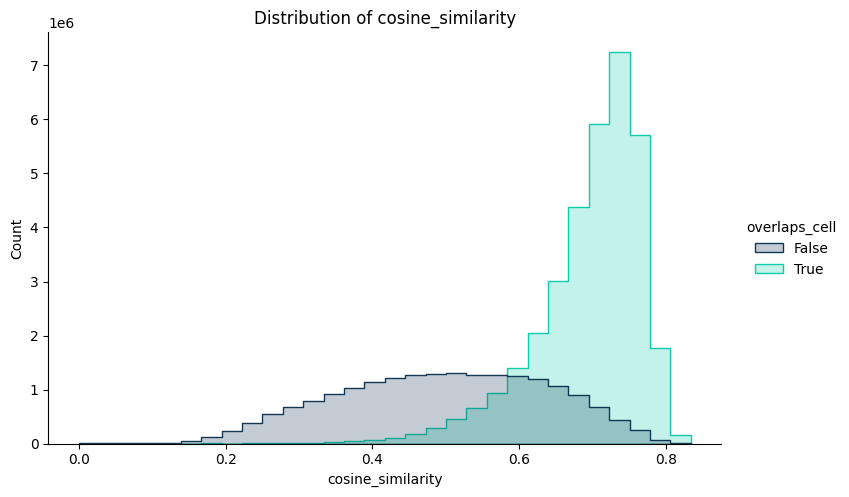

In [ ]:
inpath = "/media/sergio/Meninges/troutpy/rois/xenium_msbrain_300"  # modify this path

saving_path = os.path.join(inpath, "figures")
if not os.path.exists(saving_path):
    os.makedirs(saving_path)
sdata = sd.read_zarr(os.path.join(inpath, "data.zarr"))
metadata = pd.read_csv(os.path.join(inpath, "metadata.csv"))

# clustering cells
clustering_pipeline(sdata)

# apply sainsc
troutpy.pp.segmentation_free_sainsc(
    sdata, binsize=3, celltype_key="leiden", background_filter=0.4, gaussian_kernel_key=2.0, n_threads=16
)

troutpy.pl.histogram(
    sdata, x="cosine_similarity", hue="overlaps_cell", palette="troutpy", save=True, figures_path=saving_path
)


# we define what we consider extracellular

troutpy.pp.define_extracellular(sdata, layer="transcripts", method="sainsc", copy=False, percentile_threshold=10)

# Define path for saving figures inside function

troutpy.pl.crosstab(
    sdata,
    yvar="extracellular",
    xvar="overlaps_cell",
    normalize=False,
    cmap="troutpy",
    kind="barh",
    stacked=True,
    save=True,
    figures_path=saving_path,
    figsize=(5, 2),
)
troutpy.pl.pie(
    sdata, groupby="match_cell_signature", group_key="overlaps_cell", palette="troutpy", figures_path=saving_path
)
troutpy.pl.crosstab(
    sdata,
    xvar="extracellular",
    yvar="overlaps_cell",
    normalize=True,
    cmap="Aquas",
    kind="heatmap",
    stacked=True,
    save=True,
    figures_path=saving_path,
)

# these are outputs
proportion_of_segmented = np.sum(sdata["transcripts"]["overlaps_cell"].compute() == True) / len(
    sdata["transcripts"]["extracellular"].compute()
)
proportion_of_extracellular = np.sum(sdata["transcripts"]["extracellular"].compute() == True) / len(
    sdata["transcripts"]["extracellular"].compute()
)

# This is an important step to define bins. Square size might be the most important parameter. TBD what is optimal
troutpy.pp.aggregate_extracellular_transcripts(
    sdata, gene_key="gene", square_size=10
)  # this basically 10 microns, since xy is in microns

nneighbors = estimate_environment_neighbors(
    sdata, cell_key="table", env_key="segmentation_free_table", min_counts=5, plot=False
)

# define spatial statistics
troutpy.tl.quantify_overexpression(sdata, codeword_key="control_probe", control_codewords=[True], gene_key="gene")
troutpy.tl.extracellular_enrichment(sdata, gene_key="gene")
troutpy.tl.spatial_variability(sdata, gene_key="gene", n_neighbors=10, square_size=20)
troutpy.tl.in_out_correlation(sdata, n_neighbors=nneighbors)  # this is the good one
troutpy.tl.spatial_colocalization(sdata, threshold_colocalized=1, copy=False)

# save output
genes_prop_over_noise = (
    np.sum(sdata["xrna_metadata"].var["logfoldratio_over_noise"] > 0) / sdata["xrna_metadata"].var.shape[0]
)

# plotting
troutpy.pl.logfoldratio_over_noise(sdata, test_method="auto", palette="troutpy", figures_path=saving_path, save=True)
troutpy.pl.metric_scatter(
    sdata,
    x="logfoldratio_over_noise",
    y="extracellular_proportion",
    label_top_n_y=5,
    label_bottom_n_y=0,
    figures_path=saving_path,
    save=True,
)
troutpy.pl.metric_scatter(
    sdata,
    x="in_out_spearmanR",
    y="extracellular_proportion",
    label_top_n_x=5,
    label_bottom_n_x=5,
    figures_path=saving_path,
    save=True,
)
troutpy.pl.metric_scatter(
    sdata, x="in_out_spearmanR", y="moran_I", label_top_n_y=5, label_bottom_n_y=5, figures_path=saving_path, save=True
)
troutpy.pl.metric_scatter(
    sdata,
    x="proportion_of_colocalized",
    y="extracellular_proportion",
    label_top_n_x=5,
    label_bottom_n_x=5,
    figures_path=saving_path,
    save=True,
)

# save
sdata.write(os.path.join(inpath, "data_processed.zarr"), overwrite=True)

# Work only of exRNA that is above noise levels
troutpy.pp.filter_xrna(sdata, min_logfoldratio_over_noise=0, gene_key="gene")


troutpy.tl.compute_source_score(
    sdata, layer="transcripts", gene_key="gene", lambda_decay=0.1, copy=False, celltype_key="leiden", n_jobs=10
)
# Work on source identification
troutpy.tl.assess_diffussion(sdata, gene_key="gene", distance_key="distance")
troutpy.pl.diffusion_results(
    sdata,
    x_col="mean_displacement",
    y_col="-log_ks_pval",
    label_top_n_x=3,
    label_top_n_y=3,
    label_bottom_n_x=3,
    label_bottom_n_y=3,
    y_logscale=False,
    title=None,
    palette="troutpy",
    save=True,
    figures_path=saving_path,
    custom_plot_filename=None,
)

# troutpy.pl.diffusion_results(sdata, y_col='-log_ks_pval',y_logscale=True,figures_path=saving_path,save=True)
troutpy.pl.metric_scatter(
    sdata,
    x="mean_displacement",
    y="extracellular_proportion",
    label_top_n_y=1,
    label_top_n_x=10,
    figures_path=saving_path,
    save=True,
)
troutpy.pl.metric_scatter(
    sdata,
    x="mean_displacement",
    y="in_out_spearmanR",
    label_top_n_y=1,
    label_top_n_x=10,
    figures_path=saving_path,
    save=True,
)
sdata.write(os.path.join(inpath, "data_processed_filtered.zarr"), overwrite=True)

# these are outputs
proportion_non_diffussion = np.sum(sdata["xrna_metadata"].var["ks_pval"] < 0.05) / len(
    sdata["xrna_metadata"].var.index
)
mean_gene_displacement = np.mean(sdata["xrna_metadata"].var["mean_displacement"])

# save spatial plots
categories = [
    "mean_displacement",
    "logfoldratio_over_noise",
    "in_out_spearmanR",
    "moran_I",
    "extracellular_proportion",
    "proportion_of_colocalized",
]

batch_spatial_inout_maps(
    sdata=sdata,
    metadata_layer="xrna_metadata",
    variables=categories,
    output_dir=os.path.join(saving_path, "spatial_maps"),
    n_top=3,
    n_bottom=3,
    spot_size_cells=10,
    spot_size_extra=15,
)

# we combine all outputs into a single file



/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: Futur

KeyError: 'DeprecatedCodeword_0321'